In [1]:
import pickle

with open('MicroBooNE_data/Simulation.pkl', 'rb') as infile:
  data = pickle.load(infile)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Several columns are stored as object dtype - make everything numeric
data = data.apply(pd.to_numeric)

# Simulation categories (from the lab script). Colour and line style follow the category,
# so each category looks the same on every plot.
categories = {
    21: dict(label=r'$\nu_\mu$ CC',      color="#2a78d6", ls='-'),
    10: dict(label=r'$\nu_e$ CC',        color='#eb6834', ls='-'),
    31: dict(label='NC',                 color='#1baf7a', ls='-'),
    4:  dict(label='Cosmic mis-ID',      color='#eda100', ls='--'),
    5:  dict(label='Out of fid. volume', color='#e87ba4', ls='--'),
    7:  dict(label='EXT (beam off)',     color='#008300', ls='--'),
}

# Bookkeeping columns, not physics quantities
not_physics = ['Simulation category', 'Simulation weight', 'Subevent']
physics_vars = [v for v in data.columns if v not in not_physics]

def units(var):
    if 'energy' in var:
        return 'GeV'
    if 'momentum' in var:
        return 'GeV/c'
    if any(w in var for w in ['position', 'Distance', 'distance', 'Length']):
        return 'cm'
    return None

# Set to True to weight each event by its 'Simulation weight'
use_weights = True

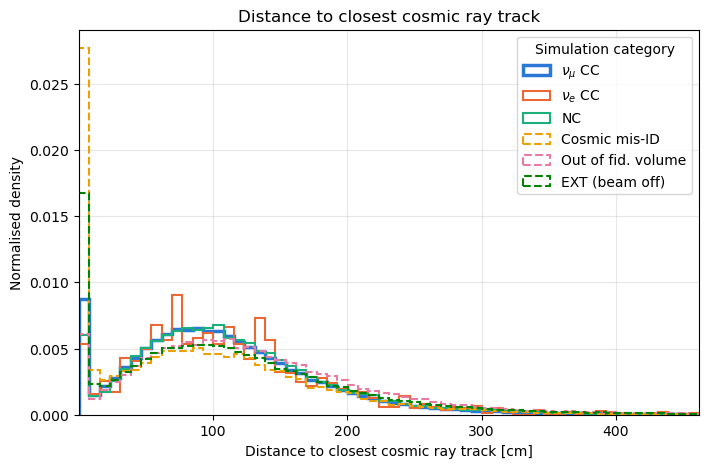

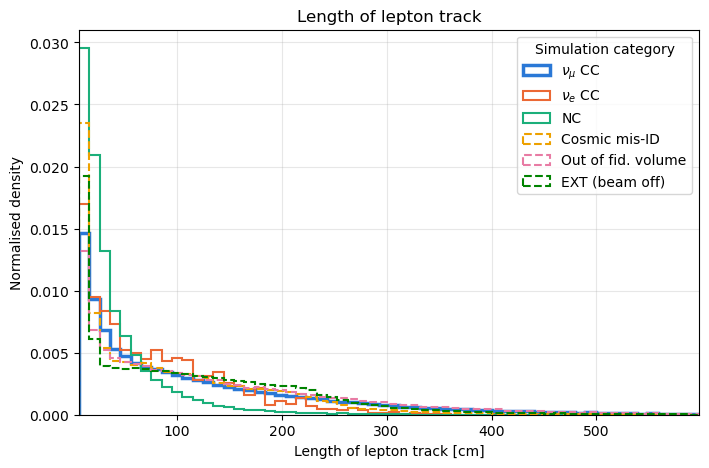

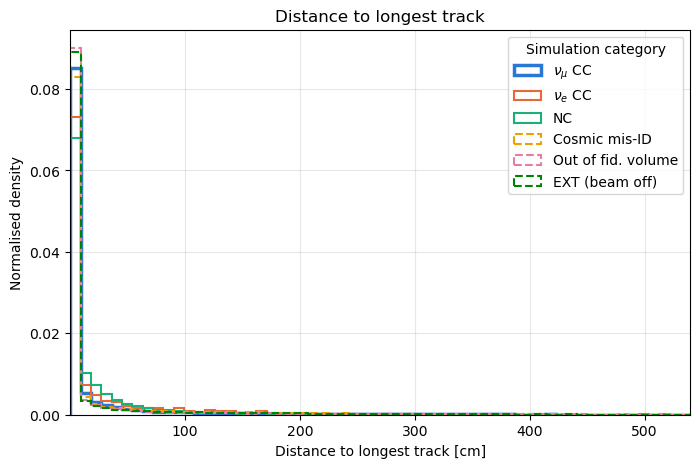

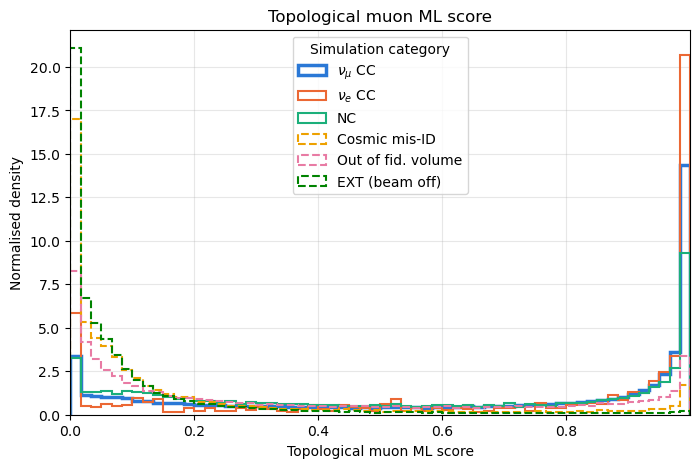

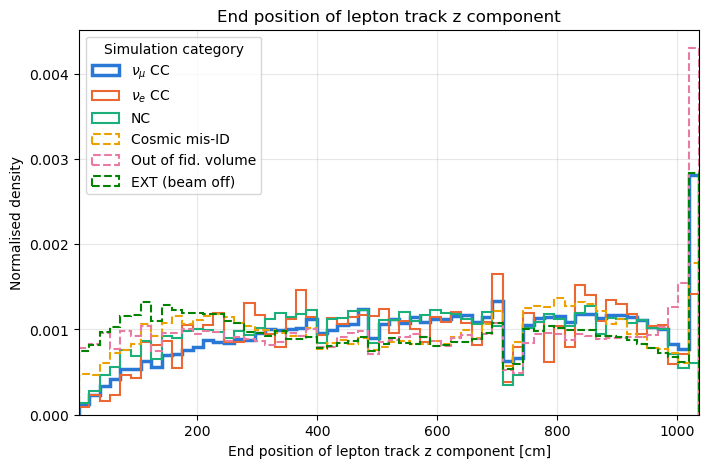

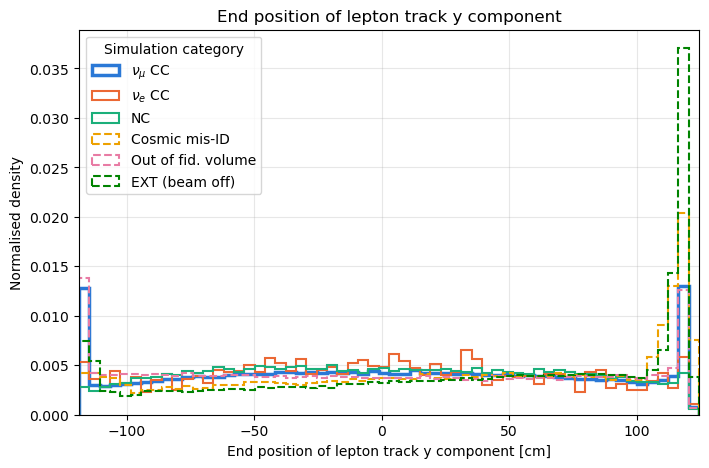

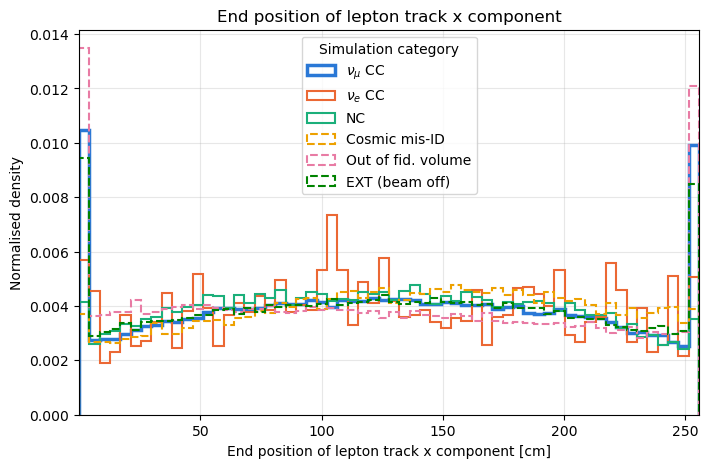

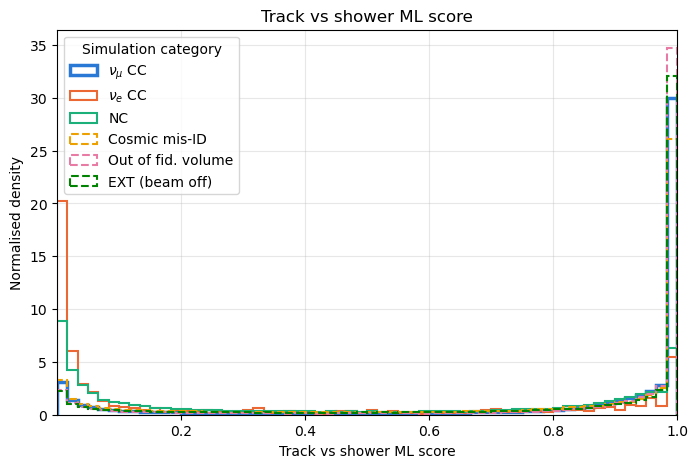

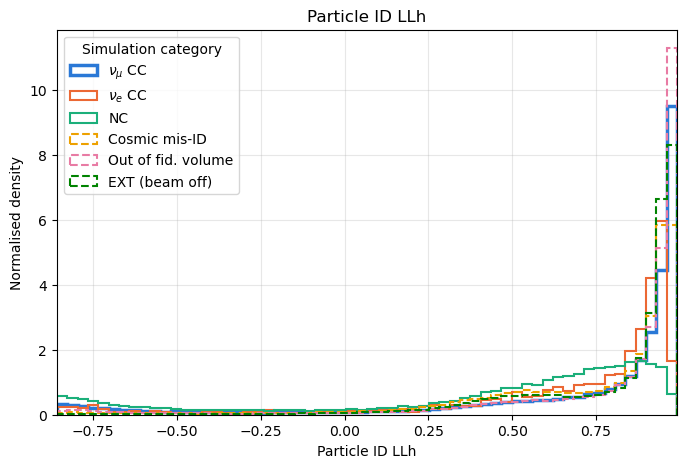

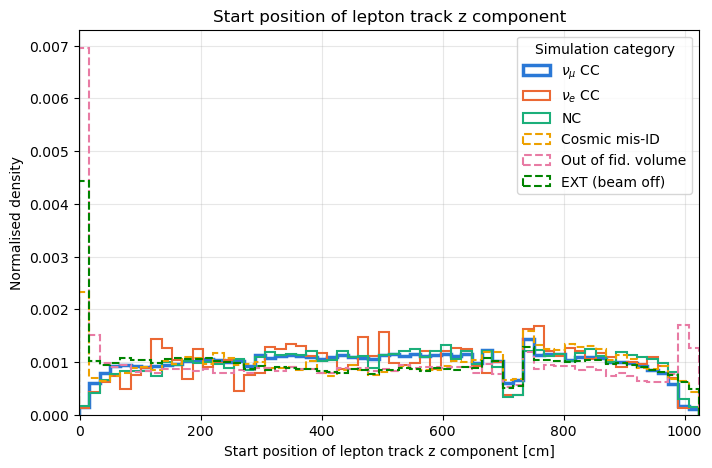

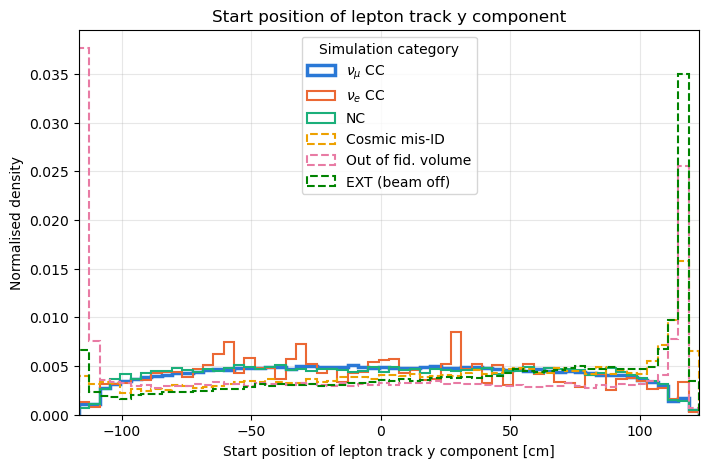

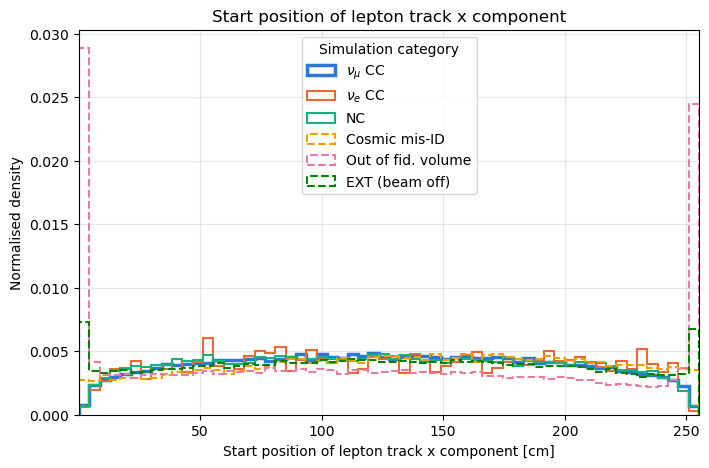

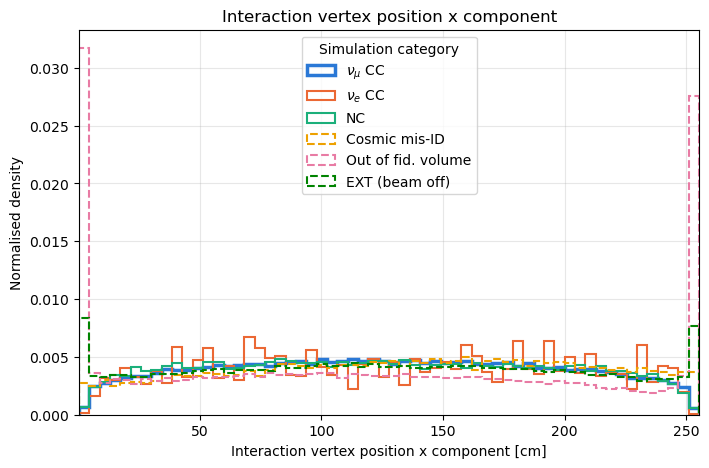

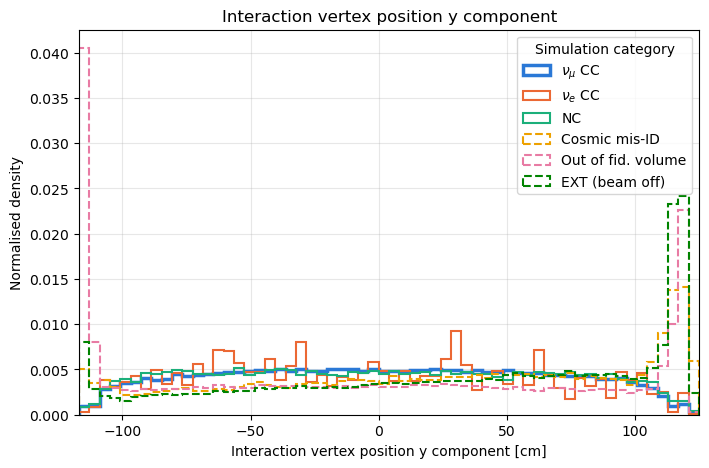

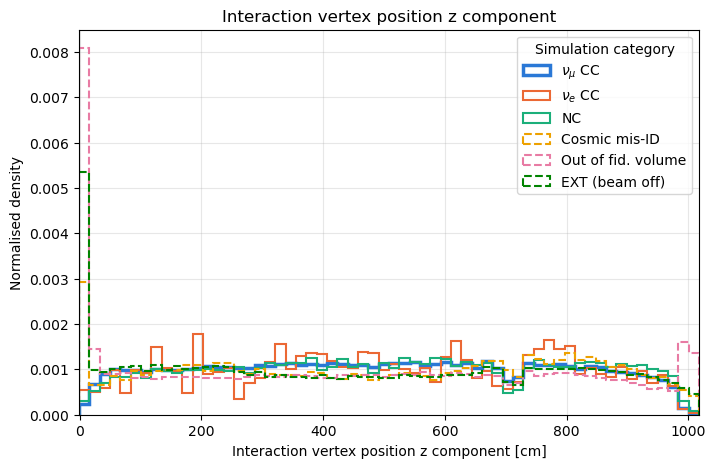

Total energy: excluding 405259 events with value ~9999


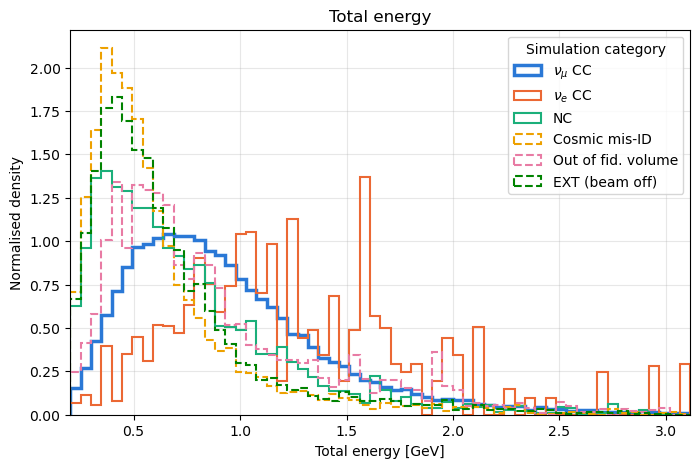

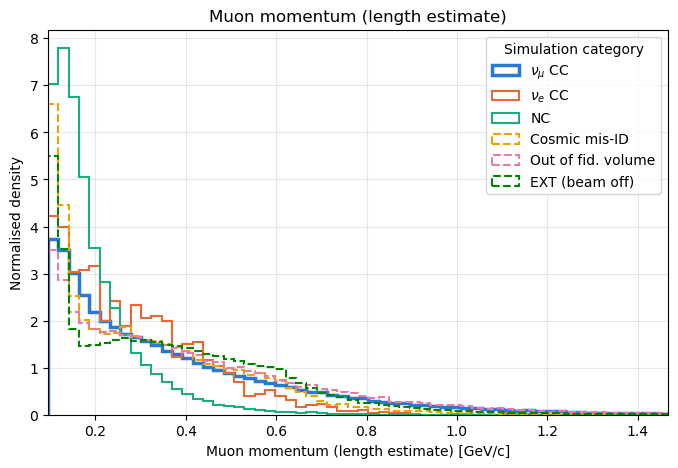

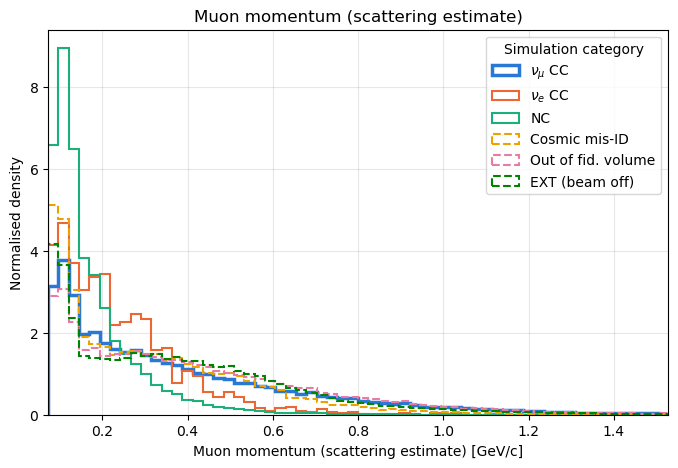

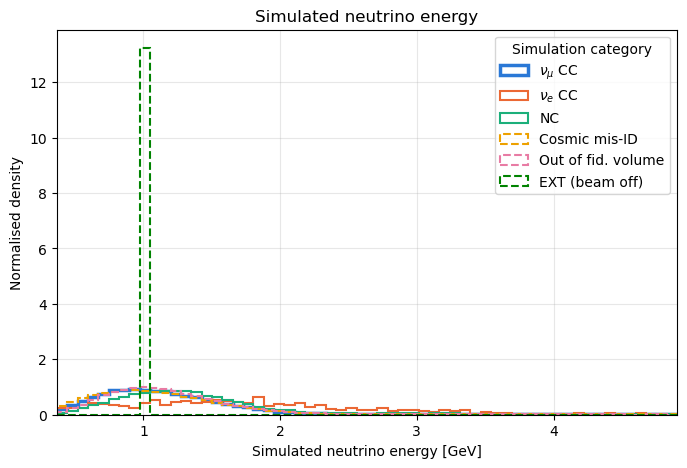

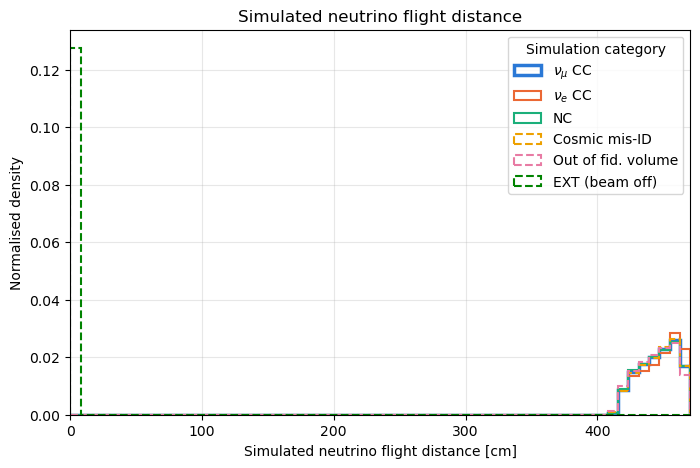

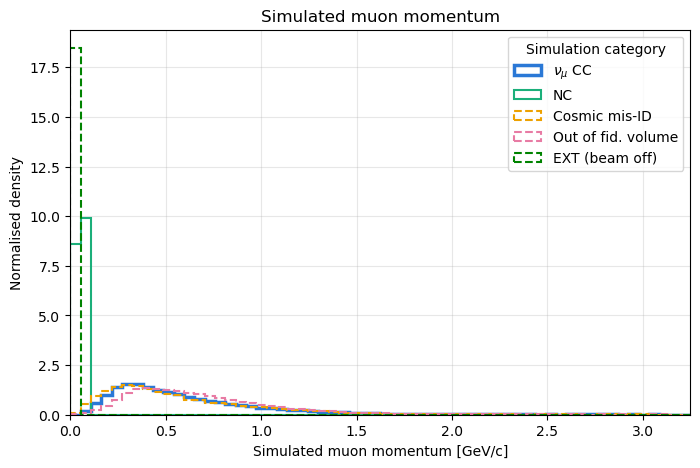

In [3]:
for var in physics_vars:
    values = data[var]
    valid = values.notna()
    if var == 'Total energy':
        # ~73% of events have a placeholder value of ~9999 - leave these out
        valid &= values < 9000
        print(f'Total energy: excluding {(values >= 9000).sum()} events with value ~9999')

    # Common bin edges for every category, clipped to the 0.5-99.5 percentile range
    # so long tails and sentinel values (e.g. -1 ML scores) don't squash the plot
    lo, hi = np.percentile(values[valid], [0.5, 99.5])
    bins = np.linspace(lo, hi, 61)

    fig, ax = plt.subplots(figsize=(8, 5))
    for cat, style in categories.items():
        sel = valid & (data['Simulation category'] == cat)
        if sel.sum() == 0:
            continue  # e.g. no simulated muon momentum for nu_e CC events
        ax.hist(values[sel], bins=bins, density=True, histtype='step',
                weights=data.loc[sel, 'Simulation weight'] if use_weights else None,
                color=style['color'], linestyle=style['ls'],
                linewidth=2.5 if cat == 21 else 1.5, label=style['label'])

    unit = units(var)
    ax.set_xlabel(f'{var} [{unit}]' if unit else var)
    ax.set_ylabel('Normalised density')
    ax.set_title(var)
    ax.set_xlim(lo, hi)
    ax.legend(title='Simulation category')
    ax.grid(alpha=0.3)
    plt.show()